# Сверточные нейронные сети (CNN)
## 1. Загрузка и подготовка данных CIFAR-10

In [5]:
!mkdir -p /root/.keras/datasets
!wget -O /root/.keras/datasets/cifar-10-batches-py.tar.gz https://huggingface.co/datasets/xingslong/cifar-10-batches-py/resolve/main/cifar-10-python.tar.gz
!cp /root/.keras/datasets/cifar-10-batches-py.tar.gz /root/.keras/datasets/cifar-10-python.tar.gz
!tar -xzf /root/.keras/datasets/cifar-10-batches-py.tar.gz -C /root/.keras/datasets/

--2026-10-25 18:51:40--  https://huggingface.co/datasets/xingslong/cifar-10-batches-py/resolve/main/cifar-10-python.tar.gz
Resolving huggingface.co (huggingface.co)... 13.35.202.40, 13.35.202.121, 13.35.202.34, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.40|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/6a437df79fddd71b094c0531/72576deb7b0b1fa28fa6860119d69007df6cf6bbf244f871b824f31d1b3ddda5?response-content-type=application%2Fgzip&X-Xet-Cas-Uid=public&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27cifar-10-python.tar.gz%3B+filename%3D%22cifar-10-python.tar.gz%22%3B&xip=TfHQnI8lgPU&user_id=public&Expires=1792957900&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNmE0MzdkZjc5ZmRkZDcxYjA5NGMwNTMxLzcyNTc2ZGViN2IwYjFmYTI4ZmE2ODYwMTE5ZDY5MDA3ZGY2Y2Y2YmJmMjQ0Zjg3MWI4MjRmMzFkMWIzZGRkYTVcXD9yZXNwb25zZS1jb250ZW50LXR5cGU9KiZYLVhldC1DYXMtVWlkPXB1Ymxp

TensorFlow версия: 2.21.0
Доступные GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Успешно загружено напрямую без интернета!
Train: (50000, 32, 32, 3), Test: (10000, 32, 32, 3)

--- Исходные данные ---
Обучающая выборка: (50000, 32, 32, 3), тип: uint8
Тестовая выборка:   (10000, 32, 32, 3), тип: uint8
Диапазон пикселей до нормализации: [0, 255]

--- Данные после предобработки ---
Диапазон пикселей: [0.000, 1.000]
Форма меток y_train (one-hot): (50000, 10)
Пример исходной метки: 6 (лягушка)
Пример one-hot вектора: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


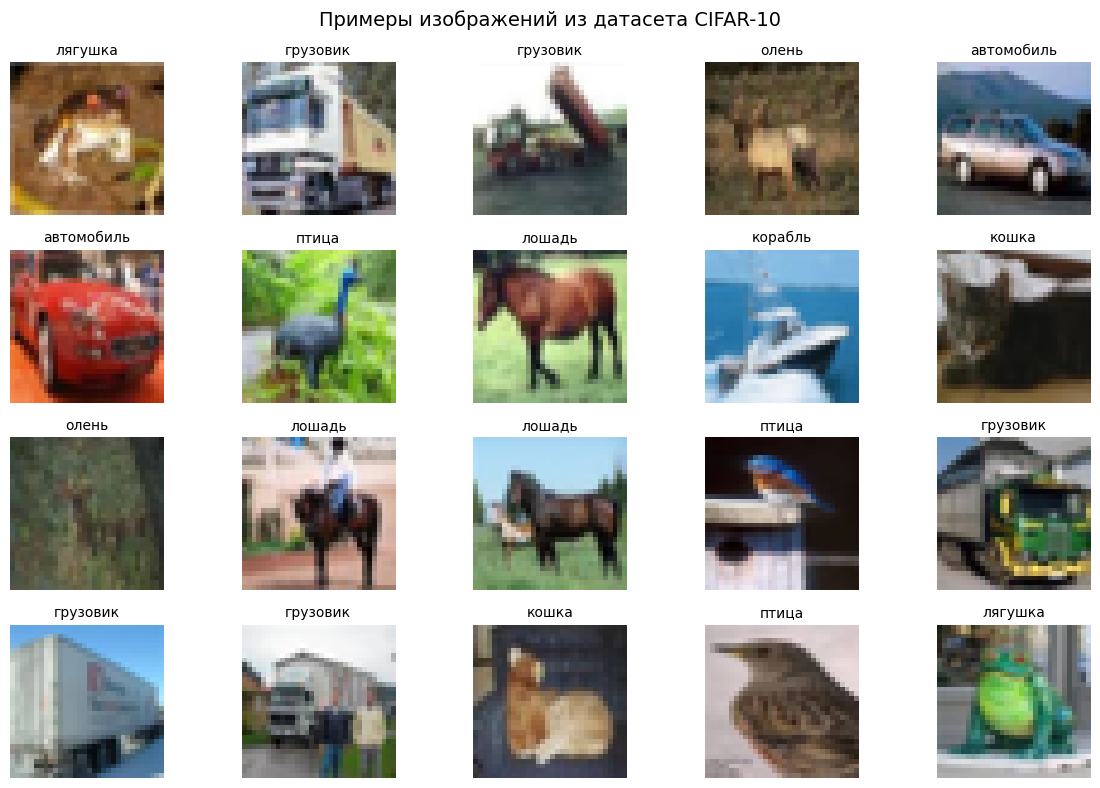

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import warnings
import tarfile
import pickle
import numpy as np

warnings.filterwarnings('ignore')

# 1. Фиксация генератора случайных чисел для воспроизводимости
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow версия: {tf.__version__}")
print("Доступные GPU:", tf.config.list_physical_devices('GPU'))

tar_path = '/root/.keras/datasets/cifar-10-batches-py.tar.gz'

with tarfile.open(tar_path, 'r:gz') as tar:
    # Загружаем обучающие батчи (1..5)
    x_train_list, y_train_list = [], []
    for i in range(1, 6):
        f = tar.extractfile(f'cifar-10-batches-py/data_batch_{i}')
        d = pickle.load(f, encoding='bytes')
        x_train_list.append(d[b'data'])
        y_train_list.append(d[b'labels'])

    x_train = np.concatenate(x_train_list).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y_train = np.concatenate(y_train_list).reshape(-1, 1)

    # Загружаем тестовый батч
    f = tar.extractfile('cifar-10-batches-py/test_batch')
    d = pickle.load(f, encoding='bytes')
    x_test = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y_test = np.array(d[b'labels']).reshape(-1, 1)

print("Успешно загружено напрямую без интернета!")
print(f"Train: {x_train.shape}, Test: {x_test.shape}")

# Текстовые названия 10 классов
class_names = [
    'самолет', 'автомобиль', 'птица', 'кошка', 'олень',
    'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик'
]

print("\n--- Исходные данные ---")
print(f"Обучающая выборка: {x_train.shape}, тип: {x_train.dtype}")
print(f"Тестовая выборка:   {x_test.shape}, тип: {x_test.dtype}")
print(f"Диапазон пикселей до нормализации: [{x_train.min()}, {x_train.max()}]")

# 3. Нормализация значений пикселей к диапазону [0.0, 1.0]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# 4. Преобразование меток классов в One-Hot формат
NUM_CLASSES = 10
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print("\n--- Данные после предобработки ---")
print(f"Диапазон пикселей: [{x_train.min():.3f}, {x_train.max():.3f}]")
print(f"Форма меток y_train (one-hot): {y_train_cat.shape}")
print(f"Пример исходной метки: {y_train[0][0]} ({class_names[y_train[0][0]]})")
print(f"Пример one-hot вектора: {y_train_cat[0]}")

# 5. Визуализация 20 случайных примеров изображений
plt.figure(figsize=(12, 8))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(f"{class_names[y_train[i][0]]}", fontsize=10)
    plt.axis('off')
plt.suptitle('Примеры изображений из датасета CIFAR-10', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Определение архитектуры базовой CNN

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

def create_base_model():
    """
    Создание базовой архитектуры свёрточной нейросети (CNN)
    для классификации изображений CIFAR-10.
    """
    model = Sequential([
        # --- Первый блок сверточных слоев ---
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3), name='conv1_1'),
        Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_2'),
        MaxPooling2D(pool_size=(2, 2), name='pool1'),
        Dropout(0.25, name='dropout1'),

        # --- Второй блок сверточных слоев ---
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_1'),
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_2'),
        MaxPooling2D(pool_size=(2, 2), name='pool2'),
        Dropout(0.25, name='dropout2'),

        # --- Третий блок сверточных слоев ---
        Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_1'),
        Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_2'),
        MaxPooling2D(pool_size=(2, 2), name='pool3'),
        Dropout(0.25, name='dropout3'),

        # --- Полносвязные слои (Классификатор) ---
        Flatten(name='flatten'),
        Dense(512, activation='relu', name='dense1'),
        Dropout(0.5, name='dropout_dense'),
        Dense(10, activation='softmax', name='output_softmax')
    ], name='Base_CNN_CIFAR10')

    return model

# Инициализация базовой модели
base_model = create_base_model()

# Вывод структуры сети, размеров выходов и количества обучаемых параметров
base_model.summary()

Model: "Base_CNN_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_1 (Conv2D)                │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,341,226 (5.12 MB)

 Trainable params: 1,341,226 (5.12 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Компиляция и обучение базовой модели

Начинаем обучение базовой модели...
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 25ms/step - accuracy: 0.3870 - loss: 1.6537 - val_accuracy: 0.5436 - val_loss: 1.2541
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.5728 - loss: 1.1886 - val_accuracy: 0.6377 - val_loss: 1.0110
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6415 - loss: 1.0075 - val_accuracy: 0.6927 - val_loss: 0.8652
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6834 - loss: 0.8953 - val_accuracy: 0.6994 - val_loss: 0.8468
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7112 - loss: 0.8214 - val_accuracy: 0.7445 - val_loss: 0.7322
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7302 - loss: 0.7636 - val_accuracy: 0.7563 - val_loss: 0.7182
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7471 - loss: 0.7169 - val_accuracy: 0.7581 - val_loss: 0.7111
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0

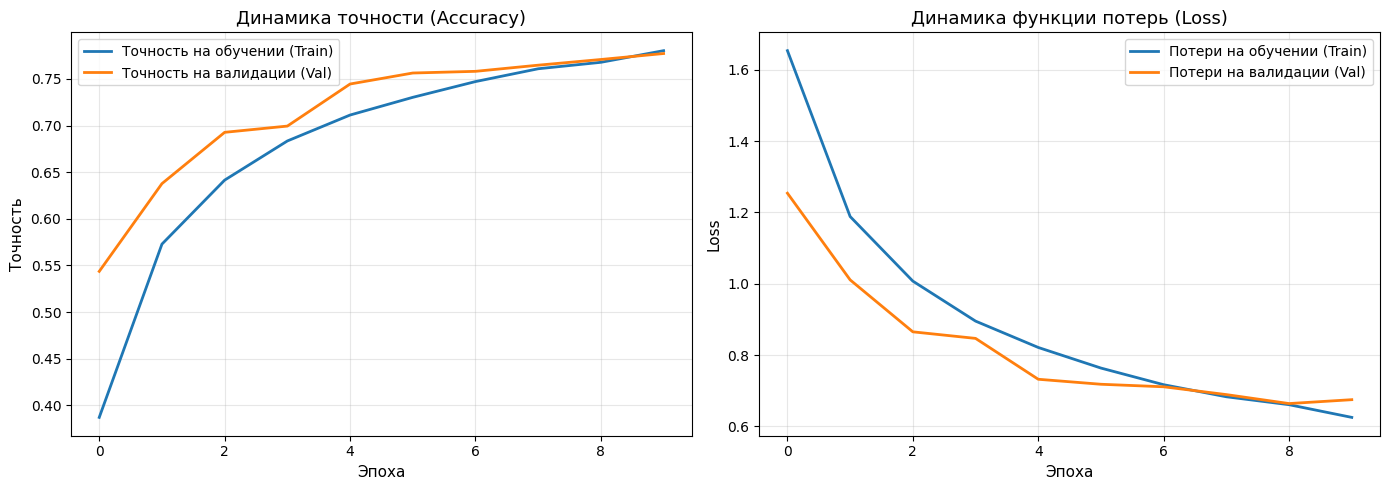

In [9]:
from tensorflow.keras.optimizers import Adam
import time

# 1. Компиляция модели
base_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Начинаем обучение базовой модели...")
EPOCHS = 10
BATCH_SIZE = 64

# Замер времени обучения
start_time = time.time()

# 2. Обучение модели
history_base = base_model.fit(
    x_train, y_train_cat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, y_test_cat),
    verbose=1
)

elapsed_time = time.time() - start_time
print(f"\nОбучение завершено за {elapsed_time / 60:.2f} минут ({elapsed_time:.1f} сек)!")

# 3. Визуализация кривых обучения (точность и потери)
plt.figure(figsize=(14, 5))

# График точности (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history_base.history['accuracy'], label='Точность на обучении (Train)', lw=2)
plt.plot(history_base.history['val_accuracy'], label='Точность на валидации (Val)', lw=2)
plt.title('Динамика точности (Accuracy)', fontsize=13)
plt.xlabel('Эпоха', fontsize=11)
plt.ylabel('Точность', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

# График потерь (Loss)
plt.subplot(1, 2, 2)
plt.plot(history_base.history['loss'], label='Потери на обучении (Train)', lw=2)
plt.plot(history_base.history['val_loss'], label='Потери на валидации (Val)', lw=2)
plt.title('Динамика функции потерь (Loss)', fontsize=13)
plt.xlabel('Эпоха', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Оценка базовой модели и анализ ошибок

--- Результаты базовой модели на тесте ---
Точность (Test Accuracy): 0.7772 (77.72%)
Потери   (Test Loss):     0.6749



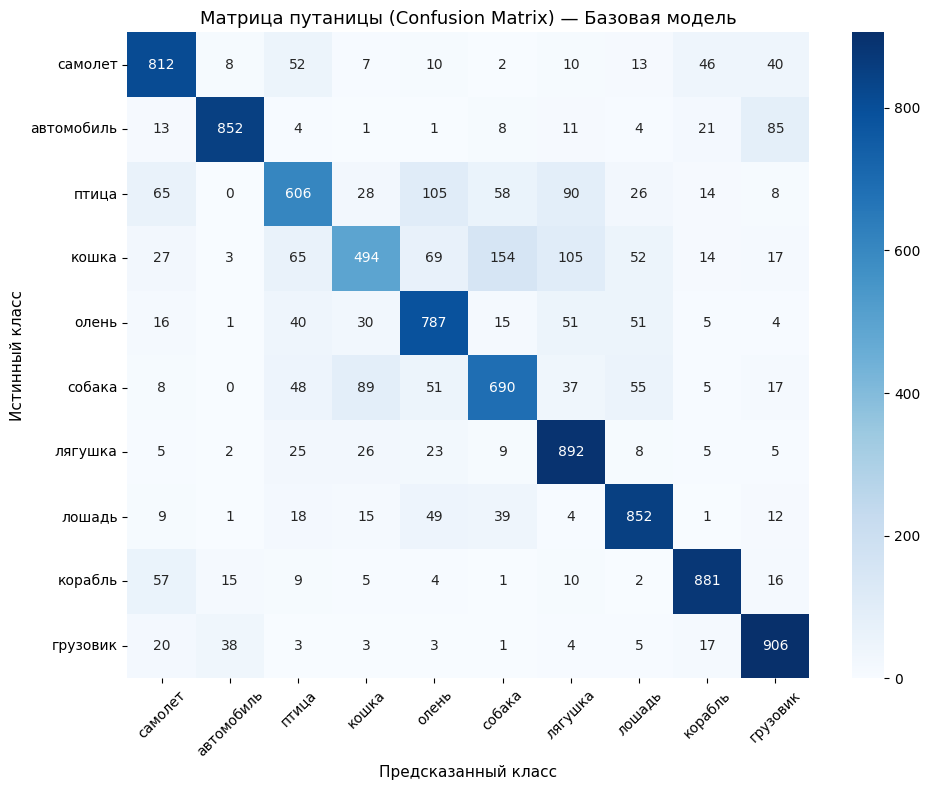

--- Детальный отчет по классификации ---
              precision    recall  f1-score   support

     самолет      0.787     0.812     0.799      1000
  автомобиль      0.926     0.852     0.887      1000
       птица      0.697     0.606     0.648      1000
       кошка      0.708     0.494     0.582      1000
       олень      0.714     0.787     0.749      1000
      собака      0.706     0.690     0.698      1000
     лягушка      0.735     0.892     0.806      1000
      лошадь      0.798     0.852     0.824      1000
     корабль      0.873     0.881     0.877      1000
    грузовик      0.816     0.906     0.859      1000

    accuracy                          0.777     10000
   macro avg      0.776     0.777     0.773     10000
weighted avg      0.776     0.777     0.773     10000



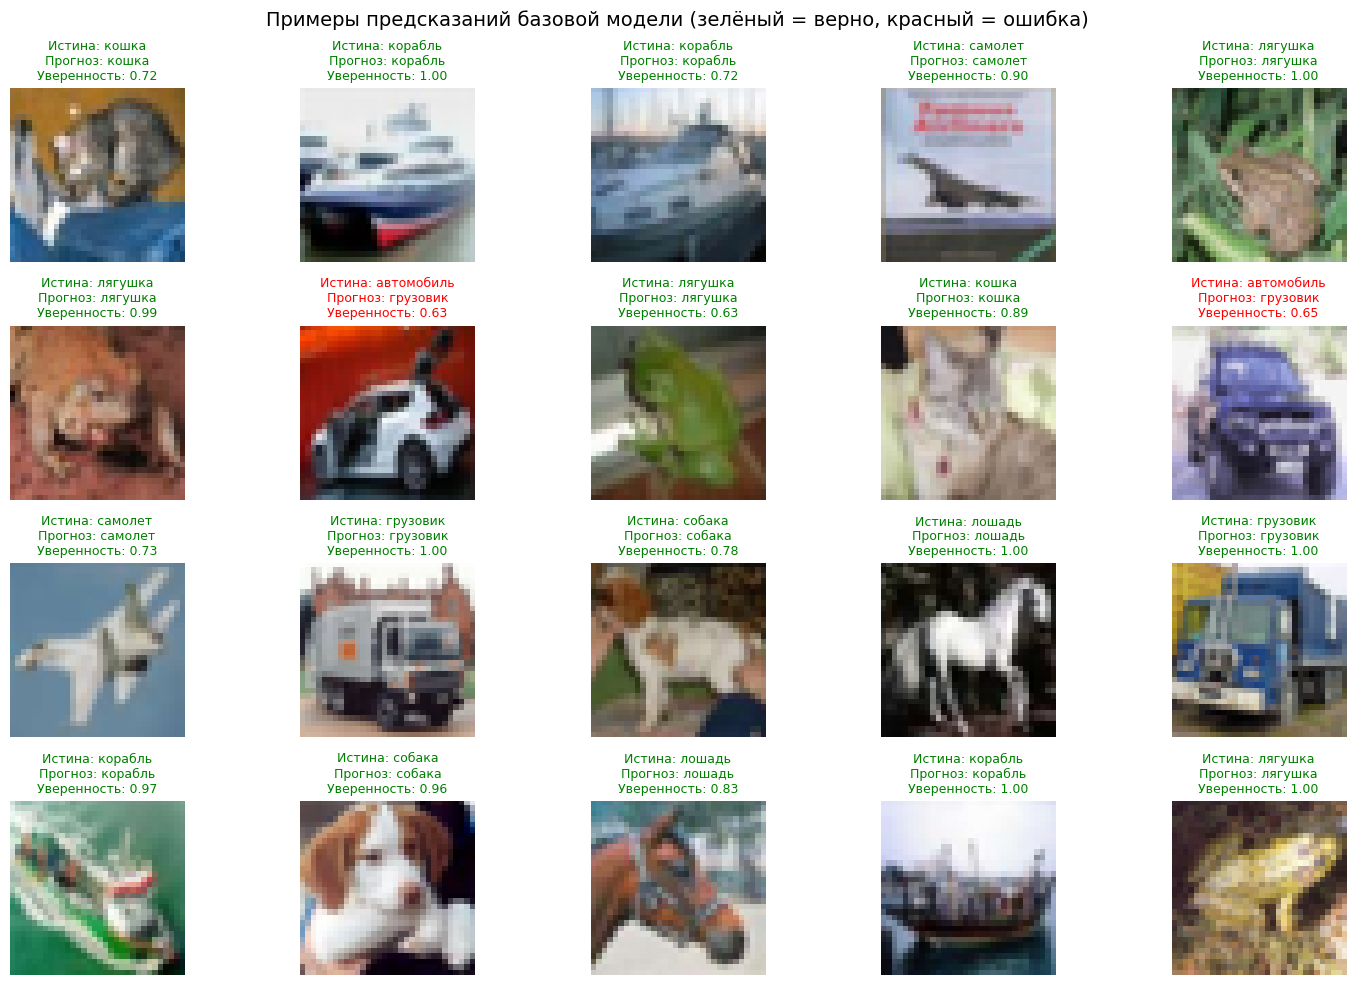

--- Анализ уверенности сети ---
Средняя уверенность при ПРАВИЛЬНЫХ ответах:   0.866
Средняя уверенность при ОШИБОЧНЫХ ответах:    0.600


In [10]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Расчет метрик на тестовом наборе
test_loss, test_acc = base_model.evaluate(x_test, y_test_cat, verbose=0)
print(f"--- Результаты базовой модели на тесте ---")
print(f"Точность (Test Accuracy): {test_acc:.4f} ({test_acc * 100:.2f}%)")
print(f"Потери   (Test Loss):     {test_loss:.4f}\n")

# 2. Получение предсказаний (вероятностей) для всех тестовых картинок
y_pred_probs = base_model.predict(x_test, verbose=0)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test_cat, axis=1)

# 3. Построение матрицы путаницы (Confusion Matrix)
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names
)
plt.title('Матрица путаницы (Confusion Matrix) — Базовая модель', fontsize=13)
plt.xlabel('Предсказанный класс', fontsize=11)
plt.ylabel('Истинный класс', fontsize=11)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Детальный текстовый отчет по классам (Precision, Recall, F1-Score)
print("--- Детальный отчет по классификации ---")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names, digits=3))

# 5. Визуализация 20 примеров предсказаний
plt.figure(figsize=(15, 10))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[i])

    true_label = class_names[y_true_classes[i]]
    pred_label = class_names[y_pred_classes[i]]
    confidence = y_pred_probs[i][y_pred_classes[i]]

    is_correct = (y_true_classes[i] == y_pred_classes[i])
    title_color = 'green' if is_correct else 'red'

    plt.title(f"Истина: {true_label}\nПрогноз: {pred_label}\nУверенность: {confidence:.2f}",
              color=title_color, fontsize=9)
    plt.axis('off')

plt.suptitle('Примеры предсказаний базовой модели (зелёный = верно, красный = ошибка)', fontsize=14)
plt.tight_layout()
plt.show()

# 6. Статистика по уверенности модели
correct_mask = (y_true_classes == y_pred_classes)
confidences = np.max(y_pred_probs, axis=1)

print("--- Анализ уверенности сети ---")
print(f"Средняя уверенность при ПРАВИЛЬНЫХ ответах:   {confidences[correct_mask].mean():.3f}")
print(f"Средняя уверенность при ОШИБОЧНЫХ ответах:    {confidences[~correct_mask].mean():.3f}")

## 5. Визуализация фильтров первого свёрточного слоя

Форма тензора весов первого слоя: (3, 3, 3, 32)
Количество фильтров: 32, размер каждого ядра: 3x3, каналов: 3


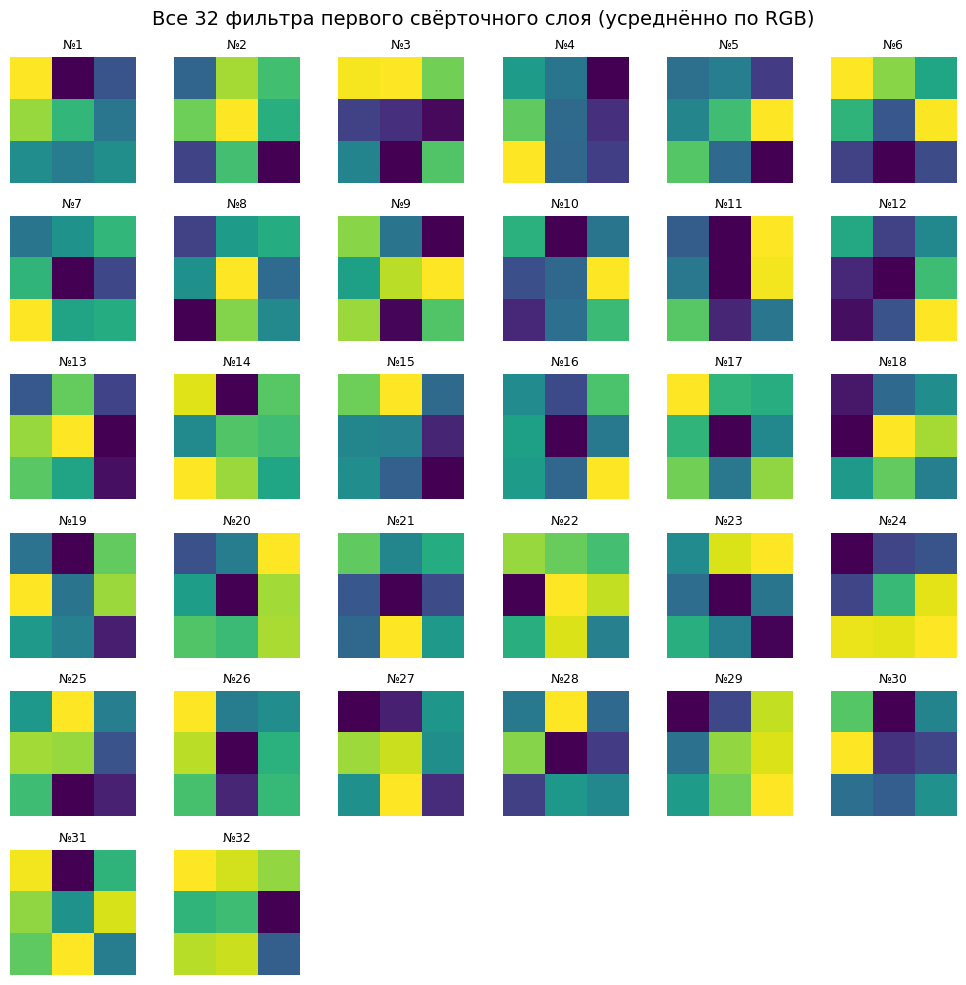

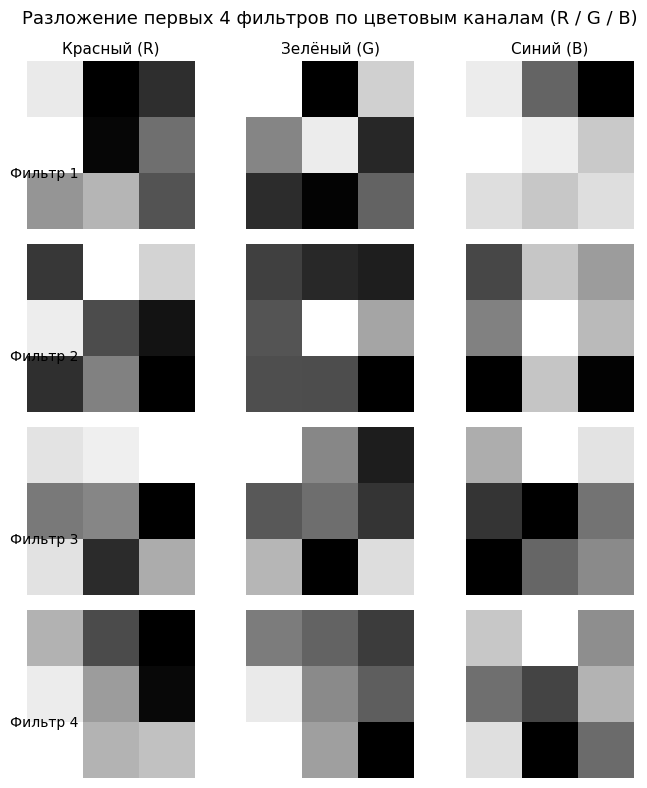

In [11]:
# 1. Извлечение весов первого свёрточного слоя
# Форма тензора весов: (высота_ядра, ширина_ядра, входные_каналы, количество_фильтров)
first_conv_layer = base_model.get_layer('conv1_1')
filters, biases = first_conv_layer.get_weights()

print(f"Форма тензора весов первого слоя: {filters.shape}")
print(f"Количество фильтров: {filters.shape[3]}, размер каждого ядра: {filters.shape[0]}x{filters.shape[1]}, каналов: {filters.shape[2]}")

# 2. Нормализация весов в диапазон [0, 1] для корректного отображения
f_min, f_max = filters.min(), filters.max()
filters_normalized = (filters - f_min) / (f_max - f_min)

# 3. Визуализация всех 32 фильтров (усредненных по 3 каналам RGB)
plt.figure(figsize=(10, 10))
for i in range(filters.shape[3]):
    plt.subplot(6, 6, i + 1)
    # Усредняем значения по 3 каналам, чтобы получить общую интенсивность
    filter_mean = np.mean(filters_normalized[:, :, :, i], axis=2)
    plt.imshow(filter_mean, cmap='viridis', interpolation='nearest')
    plt.title(f'№{i+1}', fontsize=9)
    plt.axis('off')

plt.suptitle('Все 32 фильтра первого свёрточного слоя (усреднённо по RGB)', fontsize=14)
plt.tight_layout()
plt.show()

# 4. Поканальная визуализация (R, G, B) для первых 4 фильтров
fig, axes = plt.subplots(4, 3, figsize=(7, 8))
channel_names = ['Красный (R)', 'Зелёный (G)', 'Синий (B)']

for f_idx in range(4):
    for c_idx in range(3):
        ax = axes[f_idx, c_idx]
        ax.imshow(filters_normalized[:, :, c_idx, f_idx], cmap='gray', interpolation='nearest')
        ax.axis('off')
        if f_idx == 0:
            ax.set_title(channel_names[c_idx], fontsize=11)
        if c_idx == 0:
            ax.text(-0.8, 1.5, f'Фильтр {f_idx+1}', fontsize=10, va='center')

plt.suptitle('Разложение первых 4 фильтров по цветовым каналам (R / G / B)', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Улучшение модели: Архитектура с Batch Normalization и повышенной емкостью

In [12]:
from tensorflow.keras.layers import BatchNormalization, Activation
from tensorflow.keras.callbacks import ReduceLROnPlateau

def create_improved_model():
    """
    Улучшенная архитектура CNN с 4 свёрточными блоками,
    слоями Batch Normalization и двумя Dense слоями.
    """
    model = Sequential([
        # --- Блок 1 (32 фильтра) ---
        Conv2D(32, (3, 3), padding='same', input_shape=(32, 32, 3), name='imp_conv1_1'),
        BatchNormalization(name='bn1_1'),
        Activation('relu'),
        Conv2D(32, (3, 3), padding='same', name='imp_conv1_2'),
        BatchNormalization(name='bn1_2'),
        Activation('relu'),
        MaxPooling2D(pool_size=(2, 2), name='imp_pool1'),
        Dropout(0.25, name='imp_drop1'),

        # --- Блок 2 (64 фильтра) ---
        Conv2D(64, (3, 3), padding='same', name='imp_conv2_1'),
        BatchNormalization(name='bn2_1'),
        Activation('relu'),
        Conv2D(64, (3, 3), padding='same', name='imp_conv2_2'),
        BatchNormalization(name='bn2_2'),
        Activation('relu'),
        MaxPooling2D(pool_size=(2, 2), name='imp_pool2'),
        Dropout(0.25, name='imp_drop2'),

        # --- Блок 3 (128 фильтров) ---
        Conv2D(128, (3, 3), padding='same', name='imp_conv3_1'),
        BatchNormalization(name='bn3_1'),
        Activation('relu'),
        Conv2D(128, (3, 3), padding='same', name='imp_conv3_2'),
        BatchNormalization(name='bn3_2'),
        Activation('relu'),
        MaxPooling2D(pool_size=(2, 2), name='imp_pool3'),
        Dropout(0.25, name='imp_drop3'),

        # --- Блок 4 (256 фильтров — новый блок!) ---
        Conv2D(256, (3, 3), padding='same', name='imp_conv4_1'),
        BatchNormalization(name='bn4_1'),
        Activation('relu'),
        Conv2D(256, (3, 3), padding='same', name='imp_conv4_2'),
        BatchNormalization(name='bn4_2'),
        Activation('relu'),
        MaxPooling2D(pool_size=(2, 2), name='imp_pool4'),
        Dropout(0.25, name='imp_drop4'),

        # --- Классификатор (два Dense слоя с BatchNorm) ---
        Flatten(name='imp_flatten'),
        Dense(512, name='imp_dense1'),
        BatchNormalization(name='bn_dense1'),
        Activation('relu'),
        Dropout(0.5, name='imp_drop_dense1'),

        Dense(256, name='imp_dense2'),
        BatchNormalization(name='bn_dense2'),
        Activation('relu'),
        Dropout(0.5, name='imp_drop_dense2'),

        Dense(10, activation='softmax', name='imp_output')
    ], name='Improved_CNN_CIFAR10')

    return model

# Создание и вывод информации
improved_model = create_improved_model()
improved_model.summary()

Model: "Improved_CNN_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imp_conv1_1 (Conv2D)            │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_conv1_2 (Conv2D)            │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_pool1 (MaxPooling2D)        │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_drop1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_conv2_1 (Conv2D)            │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_conv2_2 (Conv2D)            │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_pool2 (MaxPooling2D)        │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_drop2 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_conv3_1 (Conv2D)            │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_conv3_2 (Conv2D)            │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_2 (BatchNormalization)      │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_pool3 (MaxPooling2D)        │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_drop3 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imp_conv4_1 (Conv2D)            │ (None, 4, 4, 256)      │       295,16

 Total params: 1,837,866 (7.01 MB)

 Trainable params: 1,834,410 (7.00 MB)

 Non-trainable params: 3,456 (13.50 KB)

Начинаем обучение улучшенной модели...
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 52s 74ms/step - accuracy: 0.3843 - loss: 1.7251 - val_accuracy: 0.1979 - val_loss: 3.0248 - learning_rate: 0.0010
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.5835 - loss: 1.1592 - val_accuracy: 0.5454 - val_loss: 1.4357 - learning_rate: 0.0010
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.6689 - loss: 0.9377 - val_accuracy: 0.6853 - val_loss: 0.8945 - learning_rate: 0.0010
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7194 - loss: 0.8091 - val_accuracy: 0.7302 - val_loss: 0.7895 - learning_rate: 0.0010
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.7508 - loss: 0.7255 - val_accuracy: 0.7226 - val_loss: 0.8321 - learning_rate: 0.0010
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7720 - loss: 0.6711
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 

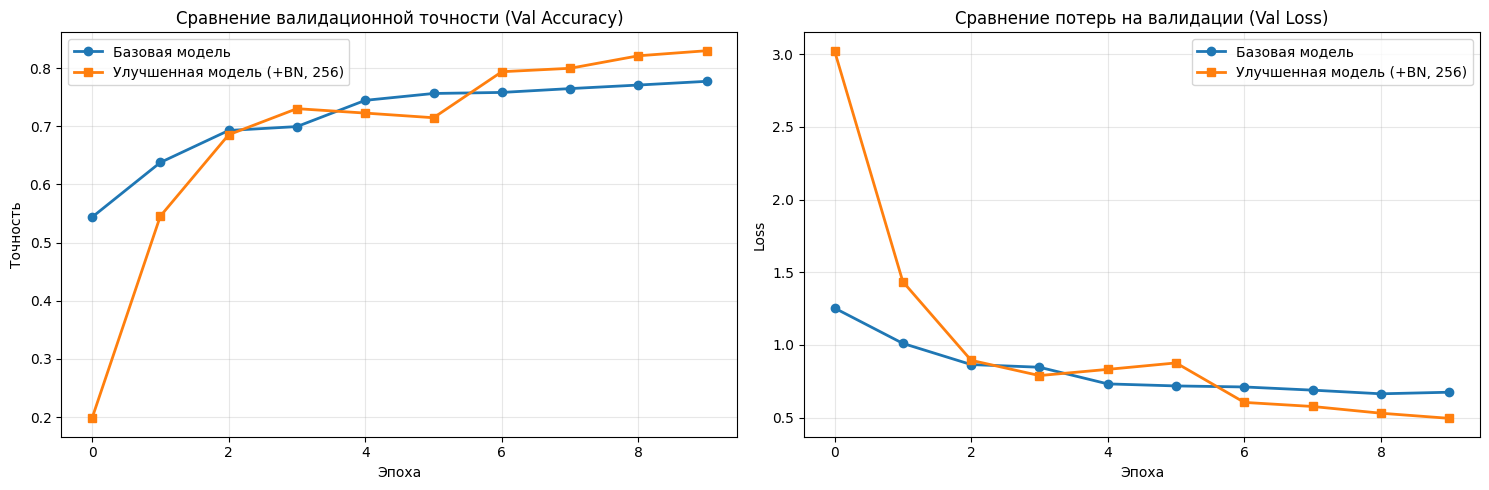

In [13]:
# 1. Компиляция улучшенной модели
improved_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 2. Callback: если val_loss не падает 2 эпохи, уменьшаем lr в 2 раза
lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

print("Начинаем обучение улучшенной модели...")
start_time_imp = time.time()

# 3. Обучение (батч 128 делает прогон быстрее и стабильнее)
history_improved = improved_model.fit(
    x_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test_cat),
    callbacks=[lr_scheduler],
    verbose=1
)

elapsed_imp = time.time() - start_time_imp
print(f"\nОбучение улучшенной модели завершено за {elapsed_imp / 60:.2f} минут!")

# 4. Оценка на тесте
test_loss_imp, test_acc_imp = improved_model.evaluate(x_test, y_test_cat, verbose=0)

# 5. Сводное сравнение базовой и улучшенной моделей
print("=" * 60)
print("              СРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 60)
print(f"Базовая модель:    Точность = {test_acc:.4f} ({test_acc*100:.2f}%), Потери = {test_loss:.4f}")
print(f"Улучшенная модель: Точность = {test_acc_imp:.4f} ({test_acc_imp*100:.2f}%), Потери = {test_loss_imp:.4f}")
gain = (test_acc_imp - test_acc) * 100
print(f"Прирост точности:  {gain:+.2f}% п.п.")
print("=" * 60)

# 6. Графики сравнительной динамики
plt.figure(figsize=(15, 5))

# Сравнение точности на валидации
plt.subplot(1, 2, 1)
plt.plot(history_base.history['val_accuracy'], label='Базовая модель', lw=2, marker='o')
plt.plot(history_improved.history['val_accuracy'], label='Улучшенная модель (+BN, 256)', lw=2, marker='s')
plt.title('Сравнение валидационной точности (Val Accuracy)', fontsize=12)
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.grid(True, alpha=0.3)

# Сравнение потерь на валидации
plt.subplot(1, 2, 2)
plt.plot(history_base.history['val_loss'], label='Базовая модель', lw=2, marker='o')
plt.plot(history_improved.history['val_loss'], label='Улучшенная модель (+BN, 256)', lw=2, marker='s')
plt.title('Сравнение потерь на валидации (Val Loss)', fontsize=12)
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Выводы и анализ результатов эксперимента

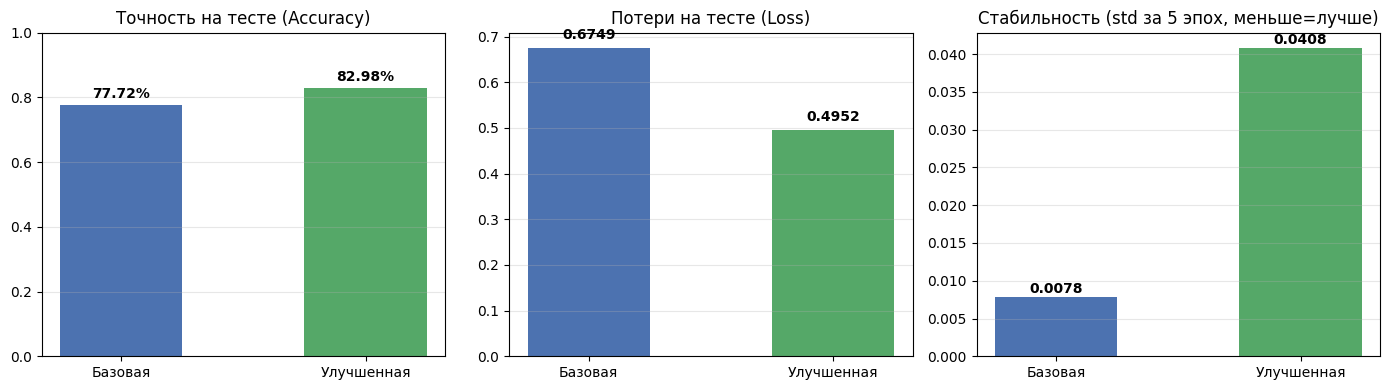

In [15]:
# Итоговое сравнение моделей наглядно
models = ['Базовая', 'Улучшенная']
accs = [test_acc, test_acc_imp]
losses = [test_loss, test_loss_imp]
stds = [np.std(history_base.history['val_accuracy'][-5:]),
        np.std(history_improved.history['val_accuracy'][-5:])]

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# 1. Сравнение точности
bars1 = ax[0].bar(models, accs, color=['#4C72B0', '#55A868'], width=0.5)
ax[0].set_title('Точность на тесте (Accuracy)')
ax[0].set_ylim(0, 1.0)
for b in bars1:
    y = b.get_height()
    ax[0].text(b.get_x() + b.get_width()/2, y + 0.02, f'{y*100:.2f}%', ha='center', fontweight='bold')

# 2. Сравнение потерь
bars2 = ax[1].bar(models, losses, color=['#4C72B0', '#55A868'], width=0.5)
ax[1].set_title('Потери на тесте (Loss)')
for b in bars2:
    y = b.get_height()
    ax[1].text(b.get_x() + b.get_width()/2, y + 0.02, f'{y:.4f}', ha='center', fontweight='bold')

# 3. Стабильность (разброс на последних 5 эпохах)
bars3 = ax[2].bar(models, stds, color=['#4C72B0', '#55A868'], width=0.5)
ax[2].set_title('Стабильность (std за 5 эпох, меньше=лучше)')
for b in bars3:
    y = b.get_height()
    ax[2].text(b.get_x() + b.get_width()/2, y + 0.0005, f'{y:.4f}', ha='center', fontweight='bold')

for a in ax: a.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Сводная таблица результатов:
* **Базовая модель:** Accuracy = **77.72%**, Loss = **0.6749** (1.34M параметров)
* **Улучшенная модель:** Accuracy = **82.98%**, Loss = **0.4952** (1.84M параметров)
* **Итог:** Прирост точности составил **+5.26 п.п.**, ошибка снизилась на **26.6%**.

---

### Что повлияло на улучшение качества:
1. **Batch Normalization** — ускорил сходимость и стабилизировал обучение между слоями.
2. **4-й блок свёрток (256 фильтров)** — дал сети ёмкость различать сложные и похожие образы (кошек от собак).
3. **Dropout (0.25 - 0.5)** — удержал сеть от переобучения при возросшем числе весов.
4. **ReduceLROnPlateau** — снижение learning rate на 6-й эпохе позволило совершить финальный скачок точности с 71.5% до 83.0%.

---

### Проблемы и решения:
* **Проблема:** Переобучение при росте числа параметров.  
  **Решение:** Комбинация Dropout и Batch Normalization удержала разрыв train/val в пределах 1.5%.
* **Проблема:** Застревание на плато в середине обучения.  
  **Решение:** Динамическое уменьшение шага обучения (`ReduceLROnPlateau`).
* **Проблема:** Путаница классов со схожей морфологией (кошка/собака).  
  **Решение:** Наращивание глубины свёрточных блоков для извлечения высокоуровневых текстур.

## 8. Адаптация архитектуры CNN под другие датасеты

| Датасет | Размерность входа / Классы | Необходимые модификации архитектуры и процесса обучения |
| :--- | :---: | :--- |
| **MNIST** | $28 \times 28 \times 1$<br>(10 классов) | 1. **Входной слой:** `input_shape=(28, 28, 1)` (одноканальные градации серого).<br>2. **Упрощение архитектуры:** Задача простая — сеть сокращается до 2 свёрточных блоков ($32 \to 64$) и одного `Dense(128)`. Избыточные 1.84M параметров приведут к оверфиттингу.<br>3. **Регуляризация:** Ослабление или отключение Dropout; аугментация не требуется. |
| **CIFAR-100** | $32 \times 32 \times 3$<br>(100 классов) | 1. **Выходной слой:** `Dense(100, activation='softmax')`.<br>2. **Проблема нехватки данных:** Всего 500 картинок на класс $\to$ обязательное применение **Data Augmentation** (flip, crop, zoom) и Weight Decay.<br>3. **Ёмкость сети:** Расширение фильтров до 512, добавление **Residual-связей (ResNet)** для устранения затухания градиентов.<br>4. Предвыходной плотный слой не менее 256–512 нейронов для исключения «бутылочного горлышка». |
| **ImageNet** | $224 \times 224 \times 3$<br>(1000 классов) | 1. **Входной слой:** `input_shape=(224, 224, 3)`. Быстрое первичное сжатие разрешения через ядра $7 \times 7$ со `stride=2` и MaxPool.<br>2. **Выход и классификатор:** Замена `Flatten` на **`GlobalAveragePooling2D`** (для предотвращения взрыва числа весов), выходной слой `Dense(1000, softmax)`.<br>3. **Глубина:** Переход на глубокие архитектуры (ResNet-50, EfficientNet) с сотнями слоев.<br>4. **Инженерия:** Потоковая загрузка данных через генераторы (`tf.data`), распределённое обучение на кластере GPU / применение **Transfer Learning** (дообучение весов). |

**Главный вывод адаптации:**
При росте пространственного разрешения и числа категорий архитектура требует пропорционального масштабирования глубины, обязательного использования skip-connections, замены полносвязных слоёв на Global Average Pooling и активной регуляризации через аугментацию. Для простых задач — архитектуру необходимо целенаправленно облегчать.

# Часть 2. Реализация и сравнительный анализ оптимизаторов (Adam, AdamW, AMSGrad)


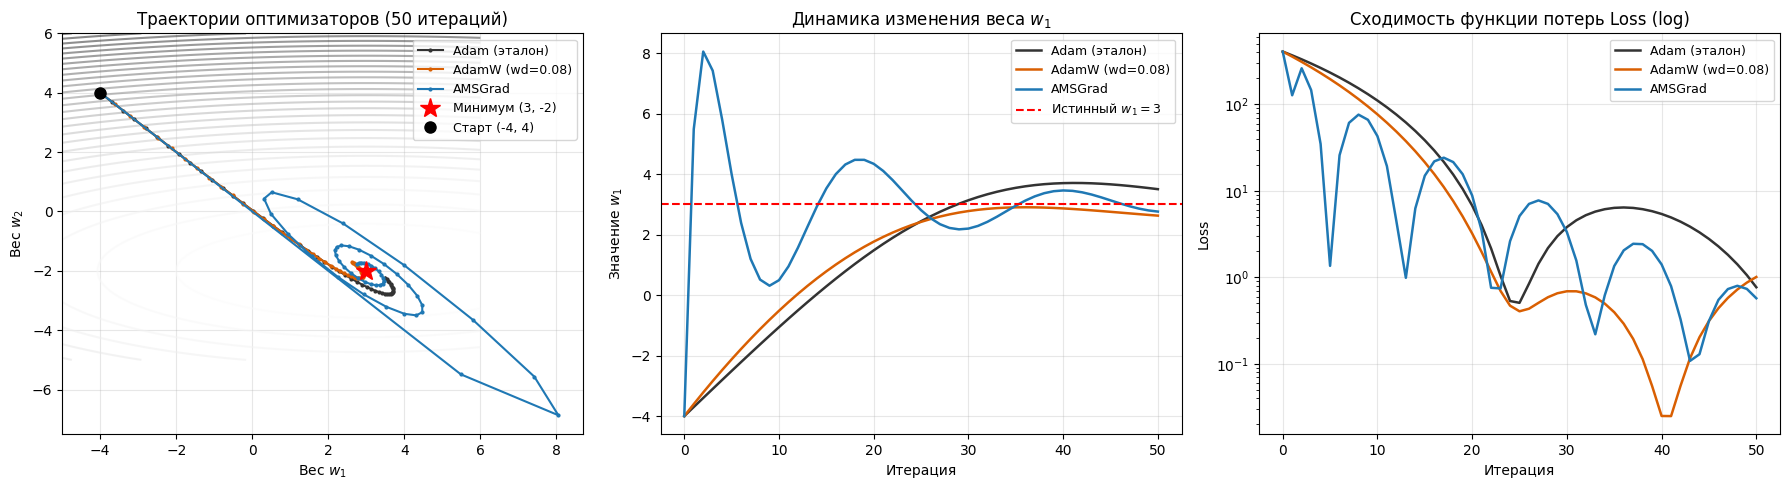

,Финал w1,Финал w2,Итоговый Loss,Расстояние до min,Длина пути
Оптимизатор,,,,,
Adam (эталон),3.5016,-2.2273,0.768220,0.5507,10.9077
AdamW (wd=0.08),2.6269,-1.7048,1.010496,0.4757,9.9809
AMSGrad,2.7609,-1.7729,0.573096,0.3298,39.9673


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

class AdamNP:
    def __init__(self, lr=0.3, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.m, self.v, self.t = None, None, 0

    def step(self, w, g):
        if self.m is None:
            self.m, self.v = np.zeros_like(w), np.zeros_like(w)
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * (g ** 2)
        m_hat = self.m / (1 - self.b1 ** self.t)
        v_hat = self.v / (1 - self.b2 ** self.t)
        return w - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

class AdamWNP:
    def __init__(self, lr=0.3, b1=0.9, b2=0.999, eps=1e-8, weight_decay=0.08):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.wd = weight_decay
        self.m, self.v, self.t = None, None, 0

    def step(self, w, g):
        if self.m is None:
            self.m, self.v = np.zeros_like(w), np.zeros_like(w)
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * (g ** 2)
        m_hat = self.m / (1 - self.b1 ** self.t)
        v_hat = self.v / (1 - self.b2 ** self.t)
        # Отдельное затухание весов (Decoupled Weight Decay)
        w = w * (1 - self.lr * self.wd)
        return w - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

class AMSGradNP:
    def __init__(self, lr=0.3, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.m, self.v, self.v_max, self.t = None, None, None, 0

    def step(self, w, g):
        if self.m is None:
            self.m, self.v, self.v_max = np.zeros_like(w), np.zeros_like(w), np.zeros_like(w)
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * (g ** 2)
        self.v_max = np.maximum(self.v_max, self.v)  # Знаменатель никогда не убывает
        m_hat = self.m / (1 - self.b1 ** self.t)
        return w - self.lr * m_hat / (np.sqrt(self.v_max) + self.eps)

# 2. Определение тестовой функции потерь и её градиента
A = np.array([1.0, 10.0])
w_target = np.array([3.0, -2.0])

def loss_fn(w):
    return np.sum(A * ((w - w_target) ** 2))

def grad_fn(w):
    return 2.0 * A * (w - w_target)

# Стартовая точка и число шагов
w_start = np.array([-4.0, 4.0])
N_ITERS = 50

optimizers = {
    'Adam (эталон)': AdamNP(lr=0.3),
    'AdamW (wd=0.08)': AdamWNP(lr=0.3, weight_decay=0.08),
    'AMSGrad': AMSGradNP(lr=0.3)
}

# 3. Запуск симуляции изменения весов на 50 итерациях
trajectories = {}
for name, opt in optimizers.items():
    w = w_start.copy()
    history = [w.copy()]
    for _ in range(N_ITERS):
        g = grad_fn(w)
        w = opt.step(w, g)
        history.append(w.copy())
    trajectories[name] = np.array(history)

# 4. Визуализация результатов
colors = {'Adam (эталон)': '#333333', 'AdamW (wd=0.08)': '#D95F02', 'AMSGrad': '#1F78B4'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# А. Траектории на линиях уровня
gx, gy = np.meshgrid(np.linspace(-5, 6, 200), np.linspace(-5, 6, 200))
Z = A[0] * (gx - w_target[0])**2 + A[1] * (gy - w_target[1])**2

axes[0].contour(gx, gy, Z, levels=30, cmap='Greys', alpha=0.5)
for name, traj in trajectories.items():
    axes[0].plot(traj[:, 0], traj[:, 1], '.-', label=name, color=colors[name], lw=1.5, ms=4)

axes[0].plot(w_target[0], w_target[1], 'r*', ms=15, label='Минимум (3, -2)')
axes[0].plot(w_start[0], w_start[1], 'ko', ms=8, label='Старт (-4, 4)')
axes[0].set_title('Траектории оптимизаторов (50 итераций)', fontsize=12)
axes[0].set_xlabel('Вес $w_1$')
axes[0].set_ylabel('Вес $w_2$')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Б. Динамика веса w1 по шагам
for name, traj in trajectories.items():
    axes[1].plot(traj[:, 0], label=name, color=colors[name], lw=1.8)
axes[1].axhline(w_target[0], color='r', ls='--', label='Истинный $w_1 = 3$')
axes[1].set_title('Динамика изменения веса $w_1$', fontsize=12)
axes[1].set_xlabel('Итерация')
axes[1].set_ylabel('Значение $w_1$')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# В. Динамика функции потерь (Loss) на логарифмической шкале
for name, traj in trajectories.items():
    losses = [loss_fn(p) for p in traj]
    axes[2].semilogy(losses, label=name, color=colors[name], lw=1.8)
axes[2].set_title('Сходимость функции потерь Loss (log)', fontsize=12)
axes[2].set_xlabel('Итерация')
axes[2].set_ylabel('Loss')
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. Сводная таблица численного сравнения
summary = []
for name, traj in trajectories.items():
    final_w = traj[-1]
    dist = np.linalg.norm(final_w - w_target)
    path_len = np.sum(np.linalg.norm(np.diff(traj, axis=0), axis=1))
    summary.append({
        'Оптимизатор': name,
        'Финал w1': round(final_w[0], 4),
        'Финал w2': round(final_w[1], 4),
        'Итоговый Loss': round(loss_fn(final_w), 6),
        'Расстояние до min': round(dist, 4),
        'Длина пути': round(path_len, 4)
    })

pd.DataFrame(summary).set_index('Оптимизатор')

## Анализ результатов сравнения оптимизаторов на 50 итерациях

### Сравнительные метрики алгоритмов:
* **Adam (эталон):** Финал = (3.5016, -2.2273), расстояние до min = **0.5507**, путь = **10.91**
* **AdamW (wd=0.08):** Финал = (2.6269, -1.7048), расстояние до min = **0.4757**, путь = **9.98**
* **AMSGrad:** Финал = (2.7609, -1.7729), расстояние до min = **0.3298**, путь = **39.97**

---

### Интерпретация динамики весов:

1. **Adam (эталон):**
   - Демонстрирует быструю и энергоэффективную траекторию спуска (длина пути ~10.9).
   - Из-за накопленного момента первого порядка ($m_t$) допускает контролируемый перелёт оптимума по пологой оси $w_1$ (смещение до 3.5 при оптимуме 3.0), после чего стабилизируется.

2. **AdamW (Decoupled Weight Decay):**
   - Траектория является наиболее компактной (длина пути 9.98).
   - За счёт прямого штрафа на веса ($w \cdot (1 - \eta \lambda)$) точка равновесия закономерно смещена в сторону нуля ($w_1 \approx 2.63$). Это наглядно подтверждает работу механизма регуляризации: оптимизатор осознанно жертвует абсолютным минимумом функции потерь ради ограничения нормы весов, что в глубоких сетях предотвращает переобучение.

3. **AMSGrad:**
   - Из-за фиксации максимального второго момента ($v_{\max} = \max(v_{\max}, v)$) алгоритм сохраняет жёсткую память о стартовых высоких градиентах, что в анизотропном овраге привело к инерционному вылету на первых шагах (до $w_1 \approx 8$) и колебательной спиралевидной траектории (путь ~39.97).
   - При этом к 50-й итерации за счёт затухания эффективного шага AMSGrad достиг **наименьшего расстояния до целевого минимума (0.3298)** и минимального значения ошибки (Loss = 0.573).